# Settings

In [ ]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/params.json"

use_nsi = True #!if using nsi, load nsi data in this order 1. zm 2. dc1 3. dc2
bf_matrix_paths = [

    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse_concat/beamformed_apodized/640_bf_IQ_zm.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse_concat/beamformed_apodized/640_bf_IQ_dc1.npy",
    # "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/mouse_concat/beamformed_apodized/640_bf_IQ_dc2.npy"

    "./data_bf/code_class_cleaning/beamformed_apodized/002_bf_classic_zm.npy",
    "./data_bf/code_class_cleaning/beamformed_apodized/002_bf_classic_dc1.npy",
    "./data_bf/code_class_cleaning/beamformed_apodized/002_bf_classic_dc2.npy"

    #"./data_bf/code_class_cleaning/beamformed_apodized/002_bf_classic_rectangle.npy"
]
complex_bf = True

#Real data settings
using_matlab_data = False
matlab_bf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/005_mouse/001_BM.mat"
interpolate_data = True

#Filters
run_hp = True  
run_SVD = False
run_pre_hp_SVD = False
run_post_hp_SVD = False
directional_filter = False
noise_filter = False

#Saving params
save_data = True
save_image = True
bf_data_path = "./data_filtered/"
folder_name = "code_class_cleaning"
beamformed_filtered_matrix_name = "002_bff_classic"

# Imports

In [26]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
import json
import os
from scipy.signal import butter, lfilter, envelope
from scipy.io import loadmat
from kneed import KneeLocator
from matplotlib.colors import LinearSegmentedColormap


import modules.dsp as dsp
import modules.filters as filters

# Import parameters

In [27]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [28]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [29]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.011827200000000001 m


# Create workspace

In [30]:
if not os.path.exists(f"{bf_data_path}{folder_name}"):
    os.makedirs(f"{bf_data_path}{folder_name}")
    print(f"Folder {bf_data_path}{folder_name} doesn't exist. Setting up the folder.")

os.makedirs(f"{bf_data_path}{folder_name}/filtered_bf", exist_ok=True)
os.makedirs(f"{bf_data_path}{folder_name}/images", exist_ok=True)

# Import BF matrix

In [31]:
if using_matlab_data:
    bf_matrix = loadmat(matlab_bf_data_path)
    bf_matrix = list(bf_matrix.values())[-1]

    if bf_matrix.ndim == 4:
        bf_matrix = np.reshape(bf_matrix, (bf_matrix.shape[0], bf_matrix.shape[1], bf_matrix.shape[2] * bf_matrix.shape[3]))
    print("Imported bf matrix with shape: ", bf_matrix.shape)
else:
    matrices_tmp = []
    for path in bf_matrix_paths:
        if not os.path.exists(path):
            raise FileNotFoundError(f"File {path} does not exist.")
        matrices_tmp.append(np.load(path))
    bf_matrix = np.concatenate(matrices_tmp, axis = 0)
    bf_matrix
    del matrices_tmp

    print("Imported bf matrix with shape: ", bf_matrix.shape)


if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]


Imported bf matrix with shape:  (600, 256, 10)


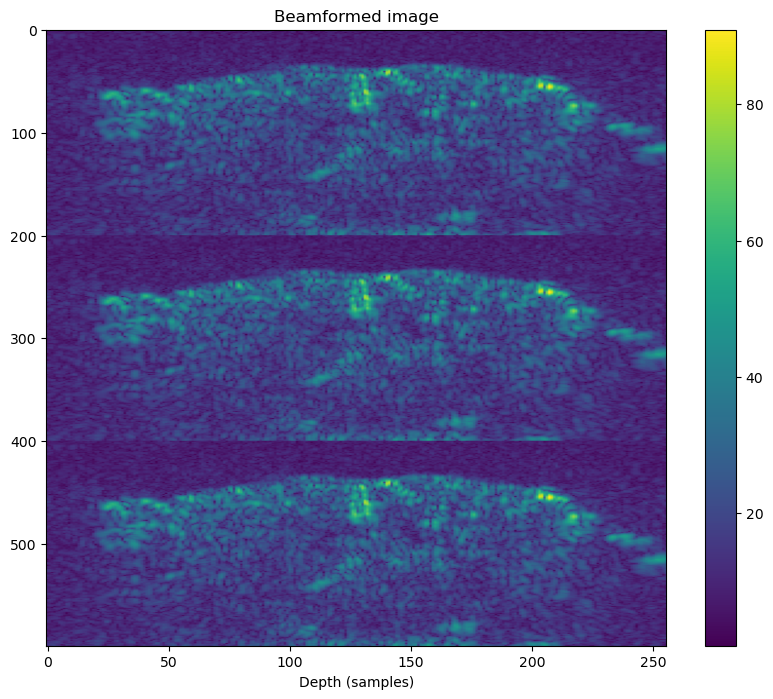

In [32]:
plt.figure(figsize=(10, 8)) 
plt.imshow(np.sqrt(np.abs(np.sum(bf_matrix, axis=2))), aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Beamformed image")
plt.xlabel("Depth (samples)")
plt.show()

In [33]:
#we start by removing the continuous component of the signal (DC offfset)
bf_matrix = bf_matrix - np.mean(bf_matrix, axis=2, keepdims=True) 

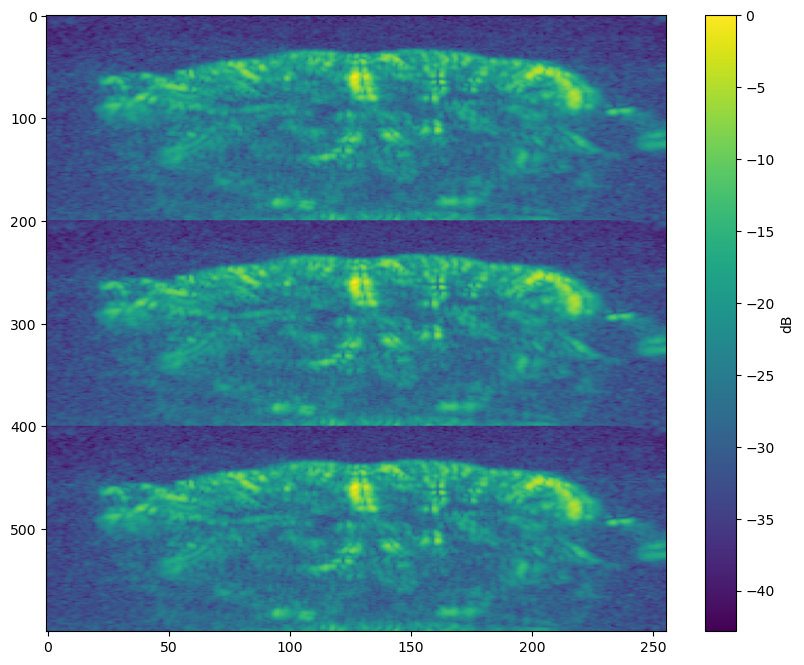

In [34]:
plt.figure(figsize=(10, 8))
plt.imshow(20 * np.log10(np.sum(np.abs(bf_matrix), axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.show()

# Save data

In [35]:
def save_beamformed_data(bf_matrix, filename, destination):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data of shape {bf_matrix.shape} saved at: {destination}{filename}.npy")

# Filters

## SVD

In [36]:
if run_SVD:
    bf_matrix, S = filters.filter_svd(bf_matrix, 6)
    plt.figure(figsize=(10, 8))
    #plt.imshow(20 * np.log10(np.sum(np.abs(bf_matrix),axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    plt.imshow(np.sqrt(np.sum(np.abs(bf_matrix),axis=2)), aspect='auto', cmap='hot')

    # plt.colorbar(label='dB')
    plt.title('SVD filtered beamformed data')

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(bf_matrix), axis=2), f"{beamformed_filtered_matrix_name}_svd", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_svd.png")
        
    plt.show()

In [37]:
if run_SVD:
    kneedle = KneeLocator(range(1, len(S) + 1), S, curve='convex', direction='decreasing')
    print(f"Optimal number of singular values to remove: {kneedle.elbow}")

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(S) + 1), S)
    plt.axvline(x=kneedle.elbow, color='r', linestyle='--')
    plt.title('Elbow Method')
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value')
    plt.grid()

## High Pass

Beamformed data of shape (600, 256) saved at: ./data_filtered/code_class_cleaning/filtered_bf/002_bff_classic_hp.npy


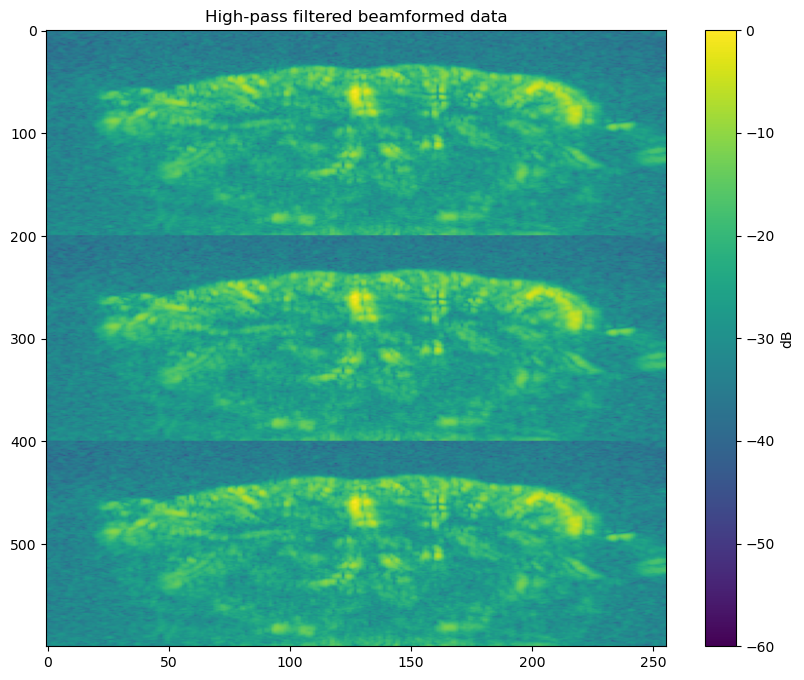

In [38]:
if run_hp:    
    bf_matrix = filters.filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 2)

    plt.figure(figsize=(10, 8))
    #plt.imshow(np.sqrt(np.sum(np.abs(bf_matrix),axis=2)), aspect='auto', cmap='viridis')
    plt.imshow(20*np.log10(np.sum(np.abs(bf_matrix),axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)

    plt.colorbar(label='dB')
    plt.title('High-pass filtered beamformed data')

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(bf_matrix), axis=2), f"{beamformed_filtered_matrix_name}_hp", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp.png")
        
    plt.show()

## HP + SVD

In [39]:
if run_pre_hp_SVD:
    # filtered_hp_svd = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 0)
    # filtered_hp_svd, S = filter_svd(filtered_hp_svd, 10)

    bf_matrix, S = filters.filter_hp_svd(bf_matrix, sampling_rate, params["rf"]["frequency"], 9)

    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.sum(np.abs(bf_matrix),axis=2)), aspect='auto', cmap='hot')
    # plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    # plt.colorbar(label='Amplitude')
    plt.title(f"Filtered HP + SVD")

    if save_data and not use_nsi:
        #save_beamformed_data(np.sum(np.abs(bf_matrix), axis=2), f"{beamformed_filtered_matrix_name}_hp_svd", f"{bf_data_path}{folder_name}/filtered_bf/")
        save_beamformed_data(bf_matrix, f"{beamformed_filtered_matrix_name}_hp_svd", f"{bf_data_path}{folder_name}/filtered_bf/")


    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp_svd.png")

    plt.show()

In [40]:
if run_pre_hp_SVD:
    kneedle = KneeLocator(range(1, len(S) + 1), S, curve='convex', direction='decreasing')
    print(f"Optimal number of singular values to remove: {kneedle.elbow}")

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(S) + 1), S)
    plt.axvline(x=kneedle.elbow, color='r', linestyle='--')
    plt.title('Elbow Method')
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value')
    plt.grid()

# Noise profile

In [41]:
if noise_filter:
    filtered_hp_svd_noise = filters.get_noise_profile(bf_matrix)
    print(f"Min noise profile: {np.min(filtered_hp_svd_noise)}, Max noise profile: {np.max(filtered_hp_svd_noise)}")
    epsilon = np.finfo(float).eps       #to avoid division by zero
    filtered_hp_svd_noise = np.maximum(filtered_hp_svd_noise, epsilon)

    bf_matrix = bf_matrix / filtered_hp_svd_noise

    plt.imshow(np.sum(filtered_hp_svd_noise, axis =2))
    plt.colorbar(label='Amp')

In [42]:
if noise_filter:
    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.sum(np.abs(bf_matrix), axis=2)), aspect='auto', cmap='hot')
    plt.title(f"Filtered HP + SVD / Noise field")

# Phase shift / Movement filter

In [43]:
bf_matrix.shape

(600, 256, 10)

In [44]:
if directional_filter: #and complex_bf:

    filtered_up, filtered_down, filtered_gray = filters.get_doppler_flow_images(bf_matrix, sampling_rate, False)

    filtered_up_sum = np.sum(np.abs(filtered_up), axis=2)
    filtered_down_sum = np.sum(np.abs(filtered_down), axis=2)

    plt.figure(figsize=(10,8))
    plt.imshow(np.sqrt(np.sum(np.abs(bf_matrix), axis = 2)), cmap='hot', aspect='auto')

In [45]:
if directional_filter: #and complex_bf:
    fig, axes = plt.subplots(nrows= 1, ncols= 2, figsize=(18,16))
    im1 = axes[0].imshow(np.sqrt(np.abs(filtered_up_sum)), cmap='hot')
    im2 =axes[1].imshow(np.sqrt(np.abs(filtered_down_sum)), cmap='hot')
    fig.colorbar(im1, label='Amplitude', ax=axes[0], shrink =0.3)
    fig.colorbar(im2, label='Amplitude', ax=axes[1], shrink =0.3)
    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.abs(filtered_up_sum)), aspect='auto', cmap='hot')
    plt.title("Filtered HP + SVD fft Up")
    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.abs(filtered_down_sum)), aspect='auto', cmap='hot')
    plt.title("Filtered HP + SVD fft Down")
    
    plt.figure(figsize=(10, 8)) 
    plt.imshow(np.sqrt(np.abs(filtered_up_sum + filtered_down_sum)), aspect='auto', cmap='hot')
    plt.title("Filtered HP + SVD fft Up + Down")
    if save_image:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp_svd_up_down.png")

In [46]:
if run_post_hp_SVD:
    filtered_down, S_down = filters.filter_hp_svd(filtered_down, sampling_rate, params["rf"]["frequency"], 5)
    filtered_up, S_up = filters.filter_hp_svd(filtered_up, sampling_rate, params["rf"]["frequency"], 5)

    # filtered_down, S_down = filters.filter_svd(filtered_down, 10)
    # filtered_up, S_up = filters.filter_svd(filtered_up, 10)

    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.sum(np.abs(filtered_down),axis=2)), aspect='auto', cmap='hot')
    plt.title(f"Filtered HP + SVD down")
    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp_svd_down.png")

    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.sum(np.abs(filtered_up),axis=2)), aspect='auto', cmap='hot')
    plt.title(f"Filtered HP + SVD up")
    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp_svd_up.png")

In [47]:
if run_post_hp_SVD:

    kneedle_down = KneeLocator(range(1, len(S_down) + 1), S_down, curve='convex', direction='decreasing')
    kneedle_up = KneeLocator(range(1, len(S_up) + 1), S_up, curve='convex', direction='decreasing')
    print(f"Optimal number of singular values to remove (down): {kneedle_down.elbow}")
    print(f"Optimal number of singular values to remove (up): {kneedle_up.elbow}")

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

    axes[0].plot(range(1, len(S_down) + 1), S_down)
    axes[0].axvline(x=kneedle_down.elbow, color='r', linestyle='--')
    axes[0].set_title('Elbow Method (Down)')
    axes[0].set_xlabel('Singular Value Index')
    axes[0].set_ylabel('Singular Value')
    axes[0].grid()

    axes[1].plot(range(1, len(S_up) + 1), S_up)
    axes[1].axvline(x=kneedle_up.elbow, color='r', linestyle='--')
    axes[1].set_title('Elbow Method (Up)')
    axes[1].set_xlabel('Singular Value Index')
    axes[1].set_ylabel('Singular Value')
    axes[1].grid()

    plt.tight_layout()

# Recombine NSI

In [48]:
#memmap_env_nsi[:,:,i] = (memmap_bf_matrix_dc1[:,:,i] + memmap_bf_matrix_dc2[:,:,i]) / 2 - memmap_bf_matrix_zm[:,:,i]

if use_nsi and not directional_filter:
    print(f"Recombining without directional filter")
    z_limit = bf_matrix.shape[0] // 3

    bff_zm = bf_matrix[:z_limit,:,:]
    bff_dc1 = bf_matrix[z_limit:z_limit*2,:,:]
    bff_dc2 = bf_matrix[z_limit*2:,:,:]

    fig, ax = plt.subplots(ncols = 3, nrows = 1, figsize=(18,10))
    im1 = ax[0].imshow(np.sqrt(np.sum(np.abs(bff_zm), axis=2)), aspect='auto', cmap='hot')
    im2 = ax[1].imshow(np.sqrt(np.sum(np.abs(bff_dc1), axis=2)), aspect='auto', cmap='hot')
    im3 = ax[2].imshow(np.sqrt(np.sum(np.abs(bff_dc2), axis=2)), aspect='auto', cmap='hot')
        
    bff_zm_env = dsp.get_envelope(bff_zm, 0, complex_bf)
    bff_dc1_env = dsp.get_envelope(bff_dc1, 0, complex_bf)
    bff_dc2_env = dsp.get_envelope(bff_dc2, 0, complex_bf)
    
    print(f"bff_zm shape: {bff_zm.shape}")
    print(f"bff_dc1 shape: {bff_dc1.shape}")
    print(f"bff_dc2 shape: {bff_dc2.shape}")

    bff_nsi = (bff_dc1_env + bff_dc2_env) / 2 - bff_zm_env
    plt.figure(figsize=(10, 8))
    # plt.imshow(20 * np.log10(np.sum(np.abs(bff_nsi),axis=2) / np.max(np.sum(np.abs(bff_nsi), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi), axis=2)), aspect='auto', cmap='hot')

    plt.title(f"NSI Filtered HP + SVD")

    if save_data:
        save_beamformed_data(np.sum(np.abs(bff_nsi), axis=2), f"{beamformed_filtered_matrix_name}_nsi", f"{bf_data_path}{folder_name}/filtered_bf/")
    if save_image:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_nsi.png")

    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(filters.get_doppler_power_image(bff_nsi)), aspect='auto', cmap='hot')
    plt.title(f"NSI Filtered HP + SVD Doppler Power Image")
    

elif use_nsi and complex_bf and directional_filter:
    print(f"Recombining with directional filter")

    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.sum(np.abs(filtered_up+filtered_down), axis=2)), aspect='auto', cmap='hot')
    plt.title("Filtered HP + SVD fft Up+Down")

    z_limit = filtered_down.shape[0] // 3

    bff_zm_down = dsp.get_envelope(filtered_down[:z_limit,:,:], 0, complex_bf)
    bff_dc1_down = dsp.get_envelope(filtered_down[z_limit:z_limit*2,:,:], 0, complex_bf)
    bff_dc2_down = dsp.get_envelope(filtered_down[z_limit*2:,:,:], 0, complex_bf)

    bff_zm_up = dsp.get_envelope(filtered_up[:z_limit,:,:], 0, complex_bf)
    bff_dc1_up = dsp.get_envelope(filtered_up[z_limit:z_limit*2,:,:], 0, complex_bf)    
    bff_dc2_up = dsp.get_envelope(filtered_up[z_limit*2:,:,:], 0, complex_bf)

    bff_nsi_fft_up = (bff_dc1_up + bff_dc2_up) / 2 - bff_zm_up 
    bff_nsi_fft_down = (bff_dc1_down + bff_dc2_down) / 2 - bff_zm_down


    fig, ax = plt.subplots(ncols = 2, nrows = 1, figsize=(18,6))

    im5 = ax[0].imshow(np.sqrt(np.sum(np.abs(bff_nsi_fft_up), axis=2)), aspect='auto', cmap='hot')
    im6 = ax[1].imshow(np.sqrt(np.sum(np.abs(bff_nsi_fft_down),axis=2)), aspect='auto', cmap='hot')
    

    ax[0].set_title("NSI FFT Up")
    ax[1].set_title("NSI FFT Down")

    # if save_data:
    #     save_beamformed_data(np.sum(np.abs(bff_nsi), axis=2), f"{beamformed_filtered_matrix_name}_nsi", f"{bf_data_path}{folder_name}/filtered_bf/")
    # if save_image:
    #     plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_nsi.png")


In [49]:
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi_fft_up), axis=2)), aspect='auto', cmap='hot')
plt.title("Up")
if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_fft_nsi_up.png")
if save_data:
    save_beamformed_data(np.sum(np.abs(bff_nsi_fft_up + bff_nsi_fft_down), axis=2), f"{beamformed_filtered_matrix_name}_fft_nsi_up", f"{bf_data_path}{folder_name}/filtered_bf/")

plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi_fft_down), axis=2)), aspect='auto', cmap='hot')
plt.title("Down")
if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_fft_nsi_down.png")
if save_data:
    save_beamformed_data(np.sum(np.abs(bff_nsi_fft_up + bff_nsi_fft_down), axis=2), f"{beamformed_filtered_matrix_name}_fft_nsi_down", f"{bf_data_path}{folder_name}/filtered_bf/")

plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi_fft_up + bff_nsi_fft_down), axis=2)), aspect='auto', cmap='hot')
plt.title("NSI fft Up + Down")
if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_fft_nsi.png")
if save_data:
    save_beamformed_data(np.sum(np.abs(bff_nsi_fft_up + bff_nsi_fft_down), axis=2), f"{beamformed_filtered_matrix_name}_fft_nsi", f"{bf_data_path}{folder_name}/filtered_bf/")

# plt.figure(figsize=(10, 8))
# plt.imshow((20*np.log10(filters.get_doppler_power_image(bff_nsi_fft_up + bff_nsi_fft_down)) - np.max(20*np.log10(filters.get_doppler_power_image(bff_nsi_fft_up + bff_nsi_fft_down)))), aspect='auto', cmap='hot')
# plt.title(f"NSI Filtered HP + SVD Doppler Power Image")
# plt.colorbar(label='dB')

NameError: name 'bff_nsi_fft_up' is not defined

<Figure size 1000x800 with 0 Axes>

In [ ]:
# if noise_filter:
#     filtered_hp_svd_noise = filters.get_noise_profile(bff_nsi)
#     print(f"Min noise profile: {np.min(filtered_hp_svd_noise)}, Max noise profile: {np.max(filtered_hp_svd_noise)}")
#     epsilon = np.finfo(float).eps       #to avoid division by zero
#     filtered_hp_svd_noise = np.maximum(filtered_hp_svd_noise, epsilon)

#     bff_nsi = bff_nsi / filtered_hp_svd_noise

#     plt.imshow(np.sum(filtered_hp_svd_noise, axis =2))
#     plt.colorbar(label='Amp')

In [ ]:
# if noise_filter:
#     plt.figure(figsize=(10, 8))
#     plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi), axis=2)), aspect='auto', cmap='hot')
#     plt.title(f"Filtered HP + SVD / Noise field")

# Colour flow

In [ ]:
if complex_bf and not use_nsi:
    filtered_up = np.sum(filtered_up, axis=2)
    filtered_down = np.sum(filtered_down, axis=2)
    filtered_gray = np.sum(filtered_gray, axis=2)

    flow_image = np.zeros((filtered_up.shape[0], filtered_up.shape[1], 3))
    flow_image[:, :, 0] = np.sqrt(np.abs(filtered_up)) / np.max(np.sqrt(np.abs(filtered_up)))
    flow_image[:, :, 2] = np.sqrt(np.abs(filtered_down)) / np.max(np.sqrt(np.abs(filtered_down)))
    flow_image[:, :, 1] = np.sqrt(np.abs(filtered_gray)) / np.max(np.sqrt(np.abs(filtered_gray)))
        
    plt.figure(figsize=(12, 10))

    plt.imshow(np.sqrt(flow_image))
    plt.title("Flow directions")
    plt.xlabel("Lateral Position (transducers)")
    plt.ylabel("Depth (samples)")


    cmap_colors = [(0, 0, 1), (0.5, 0.5, 0.5), (1, 0, 0)]  #RGB color map (in RGB format)
    custom_cmap = LinearSegmentedColormap.from_list('custom', cmap_colors)

    cb = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap),ax=plt.gca(), orientation='horizontal')
    cb.set_ticks([0, 0.5, 1])
    cb.set_ticklabels(['Downward', 'Mixed', 'Upward'])
    cb.set_label('Flow Direction')


# Benchmark results

In [ ]:
matrix_to_analyze = 20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2)))

In [ ]:
x0_noise = 30
z0_noise = 25
nx_noise = 10
nz_noise = 10


x0_roi = 85
z0_roi = 55
nx_roi = 10
nz_roi = 10

sub_plot_size = 1 if nx_roi == None or nz_roi == None else 2

fig, ax = plt.subplots(1, sub_plot_size, figsize=(15, 7))

if sub_plot_size == 1:
    ax = [ax]

#define noise region of interest
noise_matrix = matrix_to_analyze[z0_noise:z0_noise+nz_noise, x0_noise:x0_noise+nx_noise]
Pnoise = np.mean(noise_matrix)
ax[0].plot([x0_noise, x0_noise+nx_noise, x0_noise+nx_noise, x0_noise, x0_noise], [z0_noise, z0_noise, z0_noise+nz_noise, z0_noise+nz_noise, z0_noise], 'g--', label=f'ROI noise / {Pnoise:.2f} dB')


ax[0].imshow(matrix_to_analyze, aspect='auto', cmap='viridis', vmin=-60, vmax=0)
ax[0].set_xlabel("Position (samples)")
ax[0].set_ylabel("Depth (samples)")
ax[0].set_title(f"Shape: {matrix_to_analyze.shape}")

data = matrix_to_analyze[z0_roi:z0_roi+nz_roi, x0_roi:x0_roi+nx_roi]
Psignal= np.mean(data)

ax[0].plot([x0_roi, x0_roi+nx_roi, x0_roi+nx_roi, x0_roi, x0_roi], [z0_roi, z0_roi, z0_roi+nz_roi, z0_roi+nz_roi, z0_roi], 'r--', label=f'ROI signal / {Psignal:.2f} dB')
ax[0].legend()

ax[1].imshow(data, aspect='auto', cmap='viridis')
ax[1].set_xlabel("Position (samples)")
ax[1].set_ylabel("Depth (samples)")

snr_db = Psignal - Pnoise

ax[1].set_title(f"ROI Shape: {data.shape}, SNR: {snr_db:.2f} dB")

print(f"Signal: {Psignal:.2f} dB, Noise: {Pnoise:.2f} dB, SNR: {snr_db:.2f} dB")

plt.show()

In [ ]:
def visualize_directional_flow(rf_data, frames):

    amplitude = np.abs(rf_data)
    instantaneous_phase = np.angle(rf_data)

    phase_shifts = np.zeros_like(rf_data)

    
    for i in range(0, rf_data.shape[1]):    #tranducers
        for j in range(0, rf_data.shape[0]):    #samples depth
            for k in range(1 , frames):  #frames

                phase_shifts[j,i,k] = instantaneous_phase[j,i,k] - instantaneous_phase[j,i,k-1]
    
    #sum all amplitudes for frame - later for intensity
    cumulative_amplitude = np.sum(amplitude, axis=2)
    cumulative_amplitude = cumulative_amplitude / np.max(cumulative_amplitude)  #norm between 0 and 1
    
    #flow image with last axis being rgb channels 
    flow_image = np.zeros((rf_data.shape[0], rf_data.shape[1], 3))
    
    #flow image making with red and blue channels
    for i in range(0, rf_data.shape[1]):    # transducers
        for j in range(0, rf_data.shape[0]):    # samples depth
            upward_sum = 0
            downward_sum = 0
            
            for k in range(1, frames):  # frames
                phase_shift = phase_shifts[j,i,k]
                signal_amplitude = amplitude[j,i,k]
                
                if phase_shift > 0:  # up movement
                    upward_sum += signal_amplitude
                else:  # down movement
                    downward_sum += signal_amplitude
            

            total = upward_sum + downward_sum
            if total > 0:
                upward_ratio = upward_sum / total #norme once more between 0 and 1
                downward_ratio = downward_sum / total
                
                intensity = cumulative_amplitude[j,i]
                flow_image[j,i,2] = downward_ratio * intensity  #blue
                flow_image[j,i,0] = upward_ratio * intensity    #red
    
    return flow_image

In [ ]:
# up = np.load('/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse_test_pre/filtered_bf/002_bff_IQ_up_nsi.npy')
# down = np.load('/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse_test_pre/filtered_bf/002_bff_IQ_down_nsi.npy')

In [ ]:
# plt.figure(figsize=(12, 10))
# plt.imshow(np.sqrt(up))
# plt.figure(figsize=(12, 10))
# plt.imshow(np.sqrt(down))
# plt.figure(figsize=(12, 10))    
# plt.imshow(np.sqrt(up + down))